# 05 - Transfer learning: EfficientNet-B0

**Owner:** Pengzhao Wu - CSC 7333 Group 6

EfficientNet-B0 (Tan & Le, 2019) outperforms ResNet-50 on ImageNet and has around 5× fewer parameters. It uses mobile inverted bottleneck blocks with squeeze-and-excitation. Network width, depth and image size were simultaneously scaled. We replace the pretrained model's classifier with a 6-class head and fine-tune the modified model on FERPlus.

**Transfer learning in two stages**

1. *Head only*: The pretrained model is fixed and only the newly added, 6-class classifier is trained. Otherwise, a randomly initialized classifier would propagate large and erratic gradients back through the pretrained model.
2. *Fine-tuning*: The pretrained model (or only its final layers) is unfrozen and trained together with the classifier. The pretrained layers are trained at a 10× lower learning rate than the classifier.

Grayscale 224×224 images are duplicated across 3 channels and standardized using ImageNet statistics, as the pretrained model's filters are designed for this.

**Run on Colab with a GPU** (T4). On a T4 the whole notebook takes about 42 minutes, including the tuning runs. First, upload the `.npy` files to `MyDrive/ferplus/data`. Model weights and metrics are saved to `MyDrive/ferplus/`.

In [1]:
import copy
import json
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.transforms import v2

IMAGE_SIZE = 224

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Place the 9 .npy files in MyDrive/ferplus/data. Model weights and metrics are saved to MyDrive/ferplus.
    try:
        drive.mount("/content/drive")
    except Exception as err:
        print("Could not mount Google Drive, so copy the .npy files to /content/data by hand:", err)
    DRIVE = Path("/content/drive/MyDrive/ferplus")
    DATA_DIR = Path("/content/data")
    DATA_DIR.mkdir(exist_ok=True)
    # As it is slow to retrieve large arrays from Drive, required files for this notebook are copied once. The
    # 48x48 data is always required as it is used to locate test images that are also in Train.
    for file in (DRIVE / "data").glob("*.npy"):
        needed = "labels" in file.name or "_48_" in file.name or f"_{IMAGE_SIZE}_" in file.name
        if needed and not (DATA_DIR / file.name).exists():
            shutil.copy(file, DATA_DIR)
    RESULTS_DIR, MODELS_DIR = DRIVE / "results", DRIVE / "models"
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR, RESULTS_DIR, MODELS_DIR = ROOT / "data", ROOT / "results", ROOT / "models"

FIG = RESULTS_DIR / "figures"
for folder in (FIG, RESULTS_DIR / "metrics", MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("data files:", sorted(p.name for p in DATA_DIR.glob("*.npy")))

Mounted at /content/drive
data: ['FER2013Test_224_images.npy', 'FER2013Test_48_images.npy', 'FER2013Test_labels.npy', 'FER2013Train_224_images.npy', 'FER2013Train_48_images.npy', 'FER2013Train_labels.npy', 'FER2013Valid_224_images.npy', 'FER2013Valid_48_images.npy', 'FER2013Valid_labels.npy']


In [2]:
SEED = 42
CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Fear"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
MODEL_NAME = "efficientnet_b0"
# Prefix for parameter names in the new classifier section.
HEAD = "classifier"


def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels


def compute_metrics(y_true, y_pred):
    # Accuracy, macro and class level statistics and a confusion matrix. Output is in the format that notebook 06
    # expects.
    labels = range(len(CLASSES))
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1.mean(),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "per_class": {name: {"precision": precision[i], "recall": recall[i], "f1": f1[i], "support": int(support[i])}
                      for i, name in enumerate(CLASSES)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }

device: cuda | smoke test: False


## 1. Data

As with the CNN from scratch, identical data partitioning and augmentation are used. However, images are 224×224. The 224×224 training data is 1.2 GB in `uint8` format. To allow the notebook to fit into Colab's RAM, images are converted to float one batch at a time.

In [3]:
X_train, y_train = load_split("Train", IMAGE_SIZE)
X_valid, y_valid = load_split("Valid", IMAGE_SIZE)
X_test, y_test = load_split("Test", IMAGE_SIZE)
print("images:", len(X_train), len(X_valid), len(X_test))

# Test images that are identical to training images (see notebook 01). The 48x48 data contains the same images in
# the same sequence and can be compared far more swiftly.
train_bytes = {image.tobytes() for image in load_split("Train", 48)[0]}
in_train = np.array([image.tobytes() in train_bytes for image in load_split("Test", 48)[0]])


class FaceDataset(Dataset):
    # Images remain as uint8 (approximately 5 GB of memory would be required to store the 224x224 training data as
    # floats). Each image is converted at the time it is loaded.
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        image = torch.from_numpy(self.images[i]).unsqueeze(0)
        return self.transform(image), int(self.labels[i])


# The single gray channel is replicated 3 times. It is then normalized using the ImageNet mean and standard
# deviation values, as the pretrained filters require.
normalize = v2.Compose([v2.Grayscale(num_output_channels=3),
                        v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
# Random mirroring, rotation, translation and scaling plus adjustments to brightness and contrast. Only for
# training.
train_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.RandomHorizontalFlip(),
                       v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
                       v2.ColorJitter(brightness=0.2, contrast=0.2), normalize])
eval_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), normalize])

BATCH_SIZE = 64
loaders = {
    "train": DataLoader(FaceDataset(X_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    "valid": DataLoader(FaceDataset(X_valid, y_valid, eval_tf), batch_size=BATCH_SIZE, num_workers=2),
    "test": DataLoader(FaceDataset(X_test, y_test, eval_tf), batch_size=BATCH_SIZE, num_workers=2),
}

# Inverse class frequency weighting. Errors for under-represented classes (for example, Fear) are therefore
# penalized more heavily.
class_weights = len(y_train) / (len(CLASSES) * np.bincount(y_train))
print("class weights:", dict(zip(CLASSES, class_weights.round(2).tolist())))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))

{'train': 24783, 'valid': 3140, 'test': 3103}


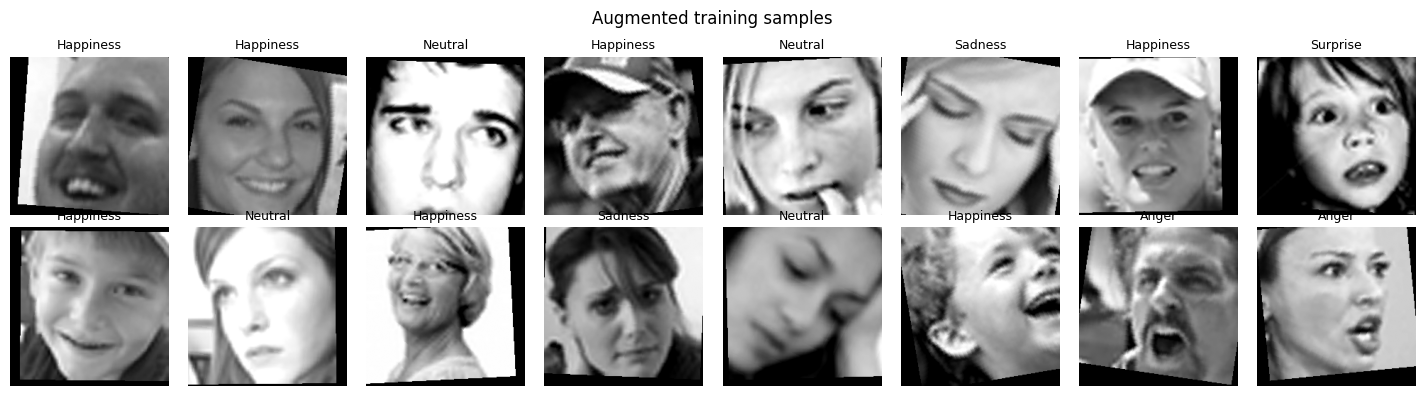

In [4]:
images, labels = next(iter(loaders["train"]))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, image, label in zip(axes.ravel(), images, labels):
    # Undoing the normalization allows the true gray levels of the face to be displayed.
    ax.imshow((image[0] * 0.229 + 0.485).clamp(0, 1), cmap="gray")
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Augmented training samples")
plt.tight_layout()
plt.show()

## 2. Model

EfficientNet-B0 consists of a stem convolution, 7 stages of MBConv blocks (`features.1` to `features.7`) and a final 1×1 convolution (`features.8`). The original classifier has been replaced by `Dropout(0.3) and Linear(1280, 6)`.

In [5]:
torch.manual_seed(SEED)
model = models.efficientnet_b0(weights="IMAGENET1K_V1")
# The 1000-class ImageNet classifier is replaced by the new 6-class classifier section.
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier[1].in_features, len(CLASSES)))
model = model.to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")
print("new head:", getattr(model, HEAD))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 169MB/s]

parameters: 4.02M
new head: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)


## 3. Stage 1: train only the new head

In [6]:
# Mixed precision approximately halves GPU training duration. However, it is disabled on the CPU.
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def run_epoch(model, loader, optimizer=None):
    # A single pass over a loader. If an optimizer is given, the model is trained. Otherwise, it is only evaluated.
    # Loss value, accuracy, macro F1 and predicted classes are returned.
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device.type, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            y_true += y.tolist()
            y_pred += logits.argmax(1).tolist()
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return total_loss / len(y_true), (y_true == y_pred).mean(), f1_score(y_true, y_pred, average="macro"), y_pred


def fit(model, optimizer, scheduler, epochs, patience, history=None):
    # Early stopping is applied according to the validation macro F1. Best model weights are reloaded at the end of
    # training. An existing history can be supplied to continue the curves of an earlier stage.
    history = {} if history is None else history
    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        start = time.time()
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc, _, _ = run_epoch(model, loaders["train"], optimizer)
        val_loss, val_acc, val_f1, _ = run_epoch(model, loaders["valid"])
        if scheduler is not None:
            scheduler.step()
        values = {"train_loss": train_loss, "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc,
                  "val_macro_f1": val_f1, "lr": lr}
        for key, value in values.items():
            history.setdefault(key, []).append(float(value))
        print(f"epoch {epoch:3d} | train loss {train_loss:.4f} acc {train_acc:.3f} | val loss {val_loss:.4f} "
              f"acc {val_acc:.3f} f1 {val_f1:.3f} | lr {lr:.1e} | {time.time() - start:.0f}s")
        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"No improvement for {patience} epochs, stopping.")
                break
    model.load_state_dict(best_state)
    history["best_val_macro_f1"] = float(best_f1)
    return history


def set_trainable(prefixes):
    # All parameters are frozen except those with names beginning with one of the given prefixes. Passing None
    # unfreezes the whole network.
    for param_name, param in model.named_parameters():
        param.requires_grad = prefixes is None or param_name.startswith(tuple(prefixes))


def make_optimizer(backbone_lr, head_lr):
    # The new classifier section is given a higher learning rate than the pretrained sections, which only require
    # slight amendment. Frozen parameters are ignored.
    head = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith(HEAD)]
    backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith(HEAD)]
    return torch.optim.AdamW([{"params": head, "lr": head_lr}, {"params": backbone, "lr": backbone_lr}],
                             weight_decay=1e-4)


STAGE1_EPOCHS = 3
HEAD_LR = 1e-3

set_trainable([HEAD])
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

start = time.time()
stage1_history = fit(model, make_optimizer(0.0, HEAD_LR), None, STAGE1_EPOCHS, patience=STAGE1_EPOCHS)
stage1_time = time.time() - start
stage1_state = copy.deepcopy(model.state_dict())

trainable parameters: 7,686


train:   0%|          | 0/388 [00:00<?, ?it/s]

epoch   1 | train loss 1.5047 acc 0.396 | val loss 1.3657 acc 0.419 f1 0.389 | lr 1.0e-03 | 72s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   2 | train loss 1.3668 acc 0.456 | val loss 1.2733 acc 0.502 f1 0.440 | lr 1.0e-03 | 69s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>self._shutdown_workers()

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
if w.is_alive():
      File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
self._shutdown_workers()    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

AssertionError    : can only test a child processif w.is_alive():

  File "/usr/lib/

epoch   3 | train loss 1.3603 acc 0.454 | val loss 1.2752 acc 0.474 f1 0.428 | lr 1.0e-03 | 71s


## 4. Stage 2 tuning: how much to unfreeze, and how fast

Every tuning run starts from the same stage-1 weights. The model is then fine-tuned for a limited number of epochs. Various combinations of pretrained model learning rate and number of retrained layers are analyzed. As before, the classifier is always trained at a 10× higher learning rate than the pretrained model. Once again, the combination of pretrained model learning rate and layer retraining that gives the highest **validation macro F1** score is selected.

In [7]:
# Prefixes for parameters that are trained during stage 2. (None indicates that all network parameters are
# trained.)
UNFREEZE = {"all": None, "last stage": ["features.6", "features.7", "features.8", "classifier"]}

TUNING_EPOCHS = 4
grid = [
    {"unfreeze": "all", "backbone_lr": 1e-4},
    {"unfreeze": "all", "backbone_lr": 3e-5},
    {"unfreeze": "last stage", "backbone_lr": 1e-4},
]


def fine_tune(params, epochs, patience, history=None):
    # Each run restarts from the weights at the end of stage 1.
    model.load_state_dict(stage1_state)
    set_trainable(UNFREEZE[params["unfreeze"]])
    optimizer = make_optimizer(params["backbone_lr"], 10 * params["backbone_lr"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return fit(model, optimizer, scheduler, epochs, patience, history)


tuning = []
for params in grid:
    print("\n", params)
    torch.manual_seed(SEED)
    history = fine_tune(params, TUNING_EPOCHS, patience=TUNING_EPOCHS)
    tuning.append({**params, "best val macro F1": round(history["best_val_macro_f1"], 4)})

tuning = pd.DataFrame(tuning).sort_values("best val macro F1", ascending=False)
tuning


 {'unfreeze': 'all', 'backbone_lr': 0.0001}


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   1 | train loss 0.9911 acc 0.622 | val loss 0.7030 acc 0.763 f1 0.695 | lr 1.0e-03 | 92s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
self._shutdown_workers()    
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (27 outputs left out)

train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   4 | train loss 0.6706 acc 0.739 | val loss 0.6586 acc 0.770 f1 0.715 | lr 1.5e-04 | 74s  *


,unfreeze,backbone_lr,best val macro F1
0,all,0.00010,0.7698
2,last stage,0.00010,0.7145
1,all,0.00003,0.6736


## 5. Stage 2: final fine-tuning

The best setting is then fine-tuned for longer. Cosine learning rate decay is applied alongside early stopping (patience = 5). The training curves continue from stage 1, and the start of fine-tuning is indicated by the dashed line.

In [8]:
best = tuning.iloc[0]
BEST = {"unfreeze": best["unfreeze"], "backbone_lr": float(best["backbone_lr"])}
STAGE2_EPOCHS = 15
print("final settings:", BEST)

torch.manual_seed(SEED)
history = copy.deepcopy(stage1_history)
# The commencement of fine-tuning (indicated by a dashed line on the graphs).
history["stage2_start"] = len(history["train_loss"]) + 1
start = time.time()
history = fine_tune(BEST, STAGE2_EPOCHS, patience=5, history=history)
train_time = stage1_time + time.time() - start
print(f"total training time: {train_time / 60:.1f} min")

final settings: {'unfreeze': 'all', 'backbone_lr': 0.0001}


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   1 | train loss 0.9911 acc 0.622 | val loss 0.7030 acc 0.763 f1 0.695 | lr 1.0e-03 | 86s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (33 outputs left out)

epoch  13 | train loss 0.1832 acc 0.914 | val loss 0.5494 acc 0.868 f1 0.823 | lr 9.5e-05 | 90s


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7fdc19445620>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

    self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    if w.is_alive():    self._shutdown_workers()

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        if w.is_alive():assert self._parent_pid == os.getpid(), 'can only test a child process'

  File "/usr/lib/python3.13/multiprocessing/process.py", line 1

epoch  14 | train loss 0.1770 acc 0.915 | val loss 0.5438 acc 0.865 f1 0.816 | lr 4.3e-05 | 92s
No improvement for 5 epochs, stopping.
total training time: 24.6 min


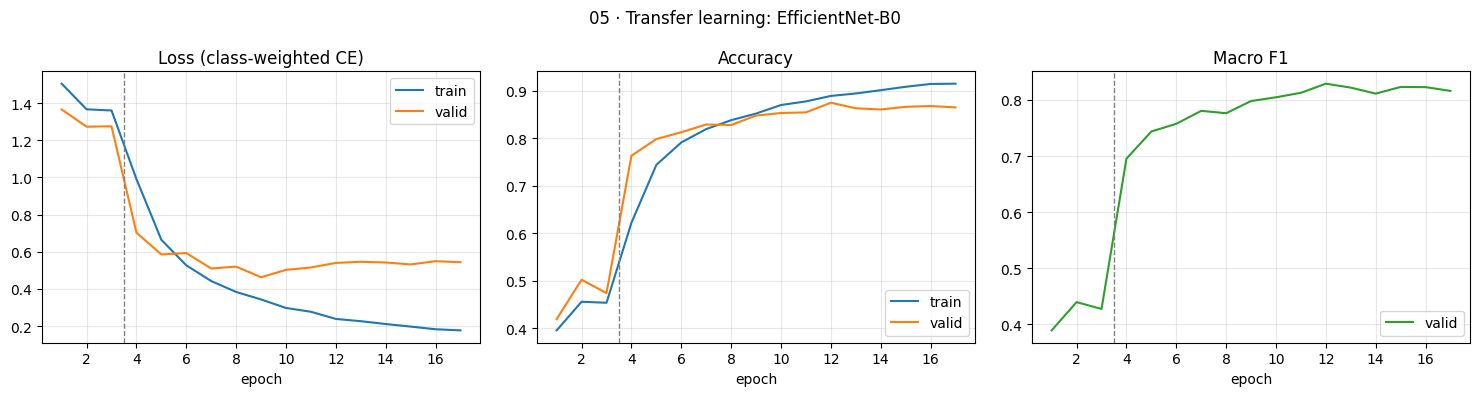

In [9]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="valid")
axes[0].set_title("Loss (class-weighted cross-entropy)")
axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["val_acc"], label="valid")
axes[1].set_title("Accuracy")
axes[2].plot(epochs, history["val_macro_f1"], color="tab:green", label="valid")
axes[2].set_title("Macro F1")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
    ax.axvline(history["stage2_start"] - 0.5, color="gray", linestyle="--", linewidth=1)
fig.suptitle("05 · Transfer learning: EfficientNet-B0")
fig.tight_layout()
fig.savefig(FIG / "efficientnet_b0_curves.png", dpi=150)
plt.show()

## 6. Test results

In [10]:
start = time.time()
_, _, _, y_pred = run_epoch(model, loaders["test"])
ms_per_image = 1000 * (time.time() - start) / len(y_test)

test_metrics = compute_metrics(y_test, y_pred)
print(f"accuracy {test_metrics['accuracy']:.4f}, macro F1 {test_metrics['macro_f1']:.4f}")
print(pd.DataFrame(test_metrics["per_class"]).T.round(3))

# Same statistics but for test images not also present in the training data.
clean_metrics = compute_metrics(y_test[~in_train], y_pred[~in_train])
print(f"\nclean test subset ({(~in_train).sum()} images): accuracy {clean_metrics['accuracy']:.4f}, "
      f"macro F1 {clean_metrics['macro_f1']:.4f}")

accuracy  0.8588
macro F1  0.8075
class        prec recall     f1      n
Neutral     0.897  0.824  0.859   1081
Happiness   0.959  0.926  0.942    891
Surprise    0.838  0.905  0.870    400
Sadness     0.670  0.802  0.730    384
Anger       0.802  0.883  0.841    266
Fear        0.677  0.543  0.603     81

clean test subset (2874 images): accuracy 0.8539, macro F1 0.7969


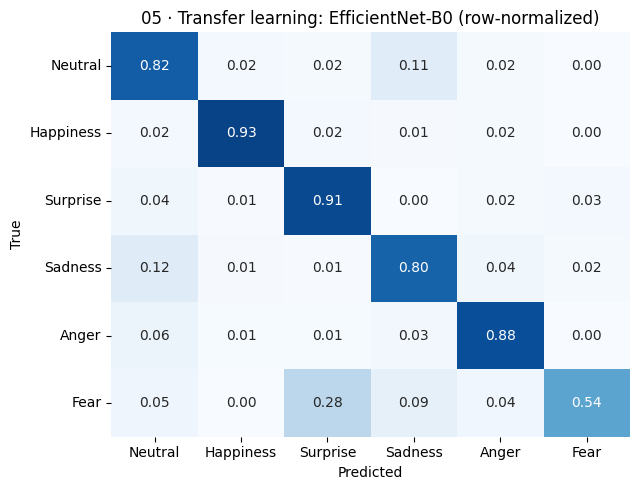

In [11]:
cm = np.array(test_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.5, 5))
# Each row is divided by its sum. Diagonal entries then indicate the recall for each class.
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(xlabel="Predicted", ylabel="True", title="05 · Transfer learning: EfficientNet-B0 (row-normalized)")
plt.tight_layout()
fig.savefig(FIG / "efficientnet_b0_confusion.png", dpi=150)
plt.show()

In [12]:
torch.save({"model_name": MODEL_NAME, "classes": CLASSES, "state_dict": model.state_dict(),
            "model_kwargs": {"dropout": 0.3}}, MODELS_DIR / f"{MODEL_NAME}.pt")

metrics = {
    "model": MODEL_NAME,
    "test": test_metrics,
    "test_clean": clean_metrics,
    "val_macro_f1": history["best_val_macro_f1"],
    "hyperparameters": {**BEST, "head_lr_stage1": HEAD_LR, "head_lr_stage2": 10 * BEST["backbone_lr"],
                        "batch_size": BATCH_SIZE, "optimizer": "AdamW", "weight_decay": 1e-4,
                        "scheduler": "CosineAnnealingLR", "stage1_epochs": STAGE1_EPOCHS,
                        "stage2_max_epochs": STAGE2_EPOCHS, "imagenet_weights": True},
    "tuning": tuning.to_dict("records"),
    "history": history,
    "parameters": sum(p.numel() for p in model.parameters()),
    "train_time_sec": round(train_time, 1),
    "inference_ms_per_image": round(ms_per_image, 3),
    "device": str(device),
}
(RESULTS_DIR / "metrics" / f"{MODEL_NAME}.json").write_text(json.dumps(metrics, indent=2))

saved /content/drive/My Drive/LSU - Masters/CSC 7333/Final Project/results/metrics/efficientnet_b0.json


## 7. Observations

_[To be completed after Colab execution.] What was achieved in stage 1? How much additional performance was gained via fine-tuning? Which layer retraining approach was most effective? How does 05 - Transfer learning: EfficientNet-B0 perform compared to the CNN from scratch?_

> **After training on Colab:** download `MyDrive/ferplus/results/metrics/efficientnet_b0.json`, along with the figures from `MyDrive/ferplus/results/figures/` and `MyDrive/ferplus/models/efficientnet_b0.pt` into the corresponding directories in the repository. Add the JSON, the graphs and the model weights (the `.pt` file) to git.